# Estudo de Caso 6.X1 — Curva de Retenção de van Genuchten: Modelagem Hidráulica de Solos Não-Saturados

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 6 — Percolação em Meio Poroso |
| **Nível** | Graduação |
| **Tempo estimado** | 45 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Avaliação algébrica direta (sem iteração temporal) |
| **Bibliografia** | Lugon Jr. et al. (2026), Cap. 6; van Genuchten (1980); Mualem (1976); Saxton & Rawls (2006) |

---

## 📋 Resumo

Exploramos o modelo de van Genuchten-Mualem para descrever as propriedades hidráulicas de solos não-saturados. Comparamos curvas de retenção $\theta(\psi)$ e condutividade hidráulica $K(\theta)$ para três texturas de solo (areia, franco e argila), analisamos o efeito dos parâmetros $\alpha$ e $n$ sobre a forma das curvas e construímos uma tabela comparativa com as propriedades hidráulicas de cada textura.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Calcular** a umidade volumétrica $\theta(\psi)$ pelo modelo de van Genuchten
2. **Calcular** a condutividade hidráulica $K(\theta)$ pelo modelo de Mualem
3. **Comparar** o comportamento hidráulico de diferentes texturas de solo
4. **Interpretar** fisicamente os parâmetros $\alpha$, $n$ e $m$ do modelo
5. **Analisar** a sensibilidade das curvas de retenção aos parâmetros do modelo
6. **Avaliar** a relação entre curva de retenção e condutividade hidráulica

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 2.3.5 | Matplotlib 3.10.6


---
## 🌡️ Seção 1: Parâmetros do Modelo de van Genuchten

### Contexto Físico

Em solos não-saturados, a água ocupa apenas parte dos poros. A relação entre o conteúdo de água $\theta$ e o potencial matricial $\psi$ (sucção) é chamada **curva de retenção de água** e é fundamental para modelar o fluxo de água em solos.

O modelo de **van Genuchten (1980)** é o mais utilizado na literatura:

$$\theta(\psi) = \theta_r + \frac{\theta_s - \theta_r}{[1 + (\alpha |\psi|)^n]^m}$$

onde:
- $\theta_r$ = umidade residual (água que permanece mesmo sob sucção muito alta)
- $\theta_s$ = umidade saturada (porosidade efetiva)
- $\alpha$ = parâmetro de entrada de ar [m⁻¹]
- $n$ = parâmetro de distribuição de poros [-]
- $m = 1 - 1/n$ = parâmetro de forma [-]

> 💡 **Observação:** A curva de retenção é sigmoidal: para sucções baixas, o solo permanece quase saturado; para sucções altas, a umidade tende a $\theta_r$.

### Tabela de Parâmetros por Textura

| Textura | $\theta_r$ | $\theta_s$ | $\alpha$ [m⁻¹] | $n$ [-] | $K_s$ [m/s] | Classificação |
|:--------|:---:|:---:|:---:|:---:|:---:|:---|
| Areia | 0,045 | 0,437 | 14,5 | 2,68 | 2,3×10⁻⁴ | Solo grosso |
| Franco | 0,078 | 0,420 | 3,6 | 1,56 | 1,0×10⁻⁶ | Solo médio |
| Argila | 0,110 | 0,450 | 0,8 | 1,09 | 1,0×10⁻⁸ | Solo fino |

In [2]:
# ============================================================
# PARÂMETROS DO MODELO — DIFERENTES TEXTURAS
# ============================================================

# Banco de dados de solos (van Genuchten, 1980; Saxton & Rawls, 2006)
solos = {
    'Areia': {
        'textura': 'Grossa',
        'theta_r': 0.045,      # Umidade residual [m³/m³]
        'theta_s': 0.437,      # Umidade saturada [m³/m³]
        'alpha': 14.5,         # Parâmetro de entrada de ar [m⁻¹]
        'n': 2.68,             # Parâmetro de distribuição de poros [-]
        'K_s': 2.3e-4,         # Condutividade saturada [m/s]
    },
    'Franco': {
        'textura': 'Média',
        'theta_r': 0.078,
        'theta_s': 0.420,
        'alpha': 3.6,
        'n': 1.56,
        'K_s': 1.0e-6,
    },
    'Argila': {
        'textura': 'Fina',
        'theta_r': 0.110,
        'theta_s': 0.450,
        'alpha': 0.8,
        'n': 1.09,
        'K_s': 1.0e-8,
    }
}

# Faixa de potencial matricial para as curvas
psi_range = -np.logspace(-3, 2, 300)   # De -0,001 a -100 m (sucção)

print('📏 Parâmetros das Texturas de Solo:')
print(f'\n{"Textura":<10}{"θ_r":<8}{"θ_s":<8}{"α [m⁻¹]":<10}{"n":<8}{"K_s [m/s]":<12}')
print('-' * 56)
for nome, params in solos.items():
    print(f'{nome:<10}{params["theta_r"]:<8.3f}{params["theta_s"]:<8.3f}'
          f'{params["alpha"]:<10.1f}{params["n"]:<8.2f}{params["K_s"]:<12.1e}')
print(f'\n  • Faixa de sucção: |ψ| = {abs(psi_range[-1]):.1e} a {abs(psi_range[0]):.1e} m')
print(f'  • Número de pontos: {len(psi_range)}')

📏 Parâmetros das Texturas de Solo:

Textura   θ_r     θ_s     α [m⁻¹]   n       K_s [m/s]   
--------------------------------------------------------
Areia     0.045   0.437   14.5      2.68    2.3e-04     
Franco    0.078   0.420   3.6       1.56    1.0e-06     
Argila    0.110   0.450   0.8       1.09    1.0e-08     

  • Faixa de sucção: |ψ| = 1.0e+02 a 1.0e-03 m
  • Número de pontos: 300


---
## 🔬 Seção 2: Verificação — Limites Físicos do Modelo

Antes de gerar as curvas, verificamos os limites físicos do modelo de van Genuchten.

### Critérios de verificação

1. **Limite de saturação:** $\theta(\psi = 0) = \theta_s$
2. **Limite residual:** $\theta(\psi \to -\infty) \to \theta_r$
3. **Monotonicidade:** $\theta$ deve ser decrescente com $|\psi|$ crescente
4. **Condutividade saturada:** $K(\theta_s) = K_s$
5. **Condutividade residual:** $K(\theta_r) \to 0$

> 📖 **Referência:** van Genuchten (1980); Lugon Jr. et al. (2026), Cap. 6, Seção 6.2.

In [3]:
# ============================================================
# FUNÇÕES DO MODELO DE VAN GENUCHTEN-MUALEM
# ============================================================

def van_genuchten_theta(psi, theta_r, theta_s, alpha, n):
    """
    Conteúdo de água θ em função do potencial matricial ψ.

    Parameters
    ----------
    psi : float ou ndarray
        Potencial matricial [m]. Valores negativos indicam solo não-saturado.
    theta_r : float
        Umidade residual [m³/m³].
    theta_s : float
        Umidade saturada [m³/m³].
    alpha : float
        Parâmetro de entrada de ar [m⁻¹].
    n : float
        Parâmetro de distribuição de poros [-].

    Returns
    -------
    float ou ndarray
        Umidade volumétrica θ [m³/m³].

    Notes
    -----
    θ(ψ) = θ_r + (θ_s - θ_r) / [1 + (α|ψ|)^n]^m
    onde m = 1 - 1/n.
    """
    m = 1.0 - 1.0 / n
    psi = np.atleast_1d(psi)

    theta = np.full_like(psi, theta_s, dtype=float)
    mask = psi < 0
    theta[mask] = theta_r + (theta_s - theta_r) / (
        1.0 + (alpha * np.abs(psi[mask]))**n)**m

    return theta


def van_genuchten_K(theta, theta_r, theta_s, K_s, n, L=0.5):
    """
    Condutividade hidráulica K em função do conteúdo de água θ.

    Parameters
    ----------
    theta : float ou ndarray
        Umidade volumétrica [m³/m³].
    theta_r : float
        Umidade residual [m³/m³].
    theta_s : float
        Umidade saturada [m³/m³].
    K_s : float
        Condutividade hidráulica saturada [m/s].
    n : float
        Parâmetro de distribuição de poros [-].
    L : float
        Parâmetro de conectividade de poros [-]. Default: 0.5 (Mualem).

    Returns
    -------
    float ou ndarray
        Condutividade hidráulica K [m/s].

    Notes
    -----
    K(θ) = K_s · Se^L · [1 - (1 - Se^(1/m))^m]²
    onde Se = (θ - θ_r) / (θ_s - θ_r) e m = 1 - 1/n.
    """
    m = 1.0 - 1.0 / n
    theta = np.atleast_1d(theta)

    # Saturação efetiva
    Se = (theta - theta_r) / (theta_s - theta_r)
    Se = np.clip(Se, 1e-10, 1.0)

    # Condutividade hidráulica relativa
    K_rel = Se**L * (1.0 - (1.0 - Se**(1.0/m))**m)**2

    return K_s * K_rel


print('✅ Funções de van Genuchten-Mualem implementadas')

✅ Funções de van Genuchten-Mualem implementadas


In [4]:
# ============================================================
# VERIFICAÇÃO — LIMITES FÍSICOS
# ============================================================

print('🔬 VERIFICAÇÃO — LIMITES FÍSICOS')
print('=' * 50)

for nome, params in solos.items():
    theta_r = params['theta_r']
    theta_s = params['theta_s']
    alpha = params['alpha']
    n = params['n']
    K_s = params['K_s']

    # Teste 1: ψ = 0 → θ = θ_s
    theta_sat = van_genuchten_theta(np.array([0.0]), theta_r, theta_s, alpha, n)[0]

    # Teste 2: ψ muito negativo → θ → θ_r
    theta_res = van_genuchten_theta(np.array([-1e6]), theta_r, theta_s, alpha, n)[0]

    # Teste 3: K(θ_s) = K_s
    K_sat = van_genuchten_K(np.array([theta_s]), theta_r, theta_s, K_s, n)[0]

    # Teste 4: K(θ_r) → 0
    K_res = van_genuchten_K(np.array([theta_r]), theta_r, theta_s, K_s, n)[0]

    print(f'\n📊 {nome}:')
    print(f'  • θ(ψ=0) = {theta_sat:.4f} (deve ser θ_s={theta_s})')
    print(f'  • θ(ψ→-∞) = {theta_res:.4f} (deve ser ≈ θ_r={theta_r})')
    print(f'  • K(θ_s) = {K_sat:.2e} m/s (deve ser K_s={K_s:.1e})')
    print(f'  • K(θ_r) = {K_res:.2e} m/s (deve ser ≈ 0)')

    assert abs(theta_sat - theta_s) < 1e-10, f'❌ θ(0) ≠ θ_s para {nome}'
    assert abs(theta_res - theta_r) < 1e-6, f'❌ θ(-∞) ≠ θ_r para {nome}'
    assert abs(K_sat - K_s) < 1e-12, f'❌ K(θ_s) ≠ K_s para {nome}'

print(f'\n✅ Todos os limites físicos verificados')

🔬 VERIFICAÇÃO — LIMITES FÍSICOS

📊 Areia:
  • θ(ψ=0) = 0.4370 (deve ser θ_s=0.437)
  • θ(ψ→-∞) = 0.0450 (deve ser ≈ θ_r=0.045)
  • K(θ_s) = 2.30e-04 m/s (deve ser K_s=2.3e-04)
  • K(θ_r) = 2.83e-41 m/s (deve ser ≈ 0)

📊 Franco:
  • θ(ψ=0) = 0.4200 (deve ser θ_s=0.42)
  • θ(ψ→-∞) = 0.0781 (deve ser ≈ θ_r=0.078)
  • K(θ_s) = 1.00e-06 m/s (deve ser K_s=1.0e-06)
  • K(θ_r) = 0.00e+00 m/s (deve ser ≈ 0)


AssertionError: ❌ θ(-∞) ≠ θ_r para Franco

---
## 📐 Seção 3: Formulação Matemática

### 3.1 Curva de Retenção (van Genuchten, 1980)

$$\theta(\psi) = \theta_r + \frac{\theta_s - \theta_r}{[1 + (\alpha |\psi|)^n]^m}, \quad \psi < 0$$

onde:
- $\psi$ = potencial matricial [m] (negativo em solo não-saturado)
- $m = 1 - 1/n$ = parâmetro de forma
- $\alpha$ está relacionado à sucção de entrada de ar: $\psi_{ae} \approx 1/\alpha$

### 3.2 Condutividade Hidráulica (Mualem, 1976)

$$K(\theta) = K_s \cdot S_e^L \left[1 - \left(1 - S_e^{1/m}\right)^m\right]^2$$

onde:
- $S_e = (\theta - \theta_r)/(\theta_s - \theta_r)$ = saturação efetiva [-]
- $L = 0{,}5$ = parâmetro de conectividade de poros (Mualem)

### 3.3 Interpretação dos Parâmetros

| Parâmetro | Efeito Físico | Valor típico |
|:----------|:--------------|:-------------|
| $\theta_r$ | Água retida por adsorção | 0,02 – 0,15 m³/m³ |
| $\theta_s$ | Porosidade efetiva | 0,35 – 0,50 m³/m³ |
| $\alpha$ | Sucção de entrada de ar ($\psi_{ae} \approx 1/\alpha$) | 0,5 – 15 m⁻¹ |
| $n$ | Uniformidade da distribuição de poros | 1,05 – 3,0 |
| $K_s$ | Condutividade saturada | 10⁻⁸ – 10⁻³ m/s |

> 📖 **Referência:** van Genuchten (1980); Mualem (1976); Lugon Jr. et al. (2026), Cap. 6, Seção 6.3.

---
## ⚡ Seção 4: Critério Numérico

> 💡 **Observação:** Neste estudo de caso, **não se aplica** a condição CFL ou critério de estabilidade temporal, pois não há equações diferenciais sendo resolvidas por métodos iterativos. As funções constitutivas são avaliadas algebricamente.

Os critérios de adequação são:

1. **Faixa de validade do modelo:** O modelo de van Genuchten é válido para $0 \leq S_e \leq 1$ e $\psi \leq 0$.

2. **Restrição $n > 1$:** O parâmetro $n$ deve ser maior que 1 para que $m = 1 - 1/n > 0$.

3. **Precisão numérica:** Para sucções muito elevadas ($|\psi| > 10^4$ m), pode haver perda de precisão. Na prática, $|\psi| > 1000$ m raramente é relevante.

4. **Resolução da curva:** Pelo menos 200 pontos em escala logarítmica para capturar a transição saturado/não-saturado.

---
## 🌪️ Seção 5: Condições de Entrada (Forçamento)

Neste problema de avaliação de funções constitutivas, o forçamento é a **faixa de potenciais matriciais**:

$$\psi \in [-100, -0{,}001] \text{ m}$$

em escala logarítmica, cobrindo desde a quase-saturação ($|\psi| = 0{,}001$ m) até a secagem extrema ($|\psi| = 100$ m).

> 💡 **Observação:** Na prática de campo, os potenciais matriciais típicos são:
> - Solo saturado: $\psi = 0$ m
> - Capacidade de campo: $\psi \approx -3{,}3$ m
> - Ponto de murcha permanente: $\psi \approx -150$ m
> - Solo seco ao ar: $\psi \approx -1000$ m

---
## 🧮 Seção 6: Implementação Numérica

In [5]:
# ============================================================
# GERAÇÃO DAS CURVAS DE RETENÇÃO
# ============================================================

t_inicio = time.time()

# Armazenar resultados
resultados = {}

for nome, params in solos.items():
    theta_range = van_genuchten_theta(
        psi_range,
        params['theta_r'],
        params['theta_s'],
        params['alpha'],
        params['n']
    )

    K_range = van_genuchten_K(
        theta_range,
        params['theta_r'],
        params['theta_s'],
        params['K_s'],
        params['n']
    )

    resultados[nome] = {
        'theta': theta_range,
        'K': K_range,
        'params': params
    }

t_cpu_curvas = time.time() - t_inicio

print('🧮 GERAÇÃO DAS CURVAS DE RETENÇÃO')
print('=' * 50)
for nome in solos:
    print(f'  • {nome}: θ ∈ [{resultados[nome]["theta"].min():.3f}, '
          f'{resultados[nome]["theta"].max():.3f}] m³/m³')
    print(f'         K ∈ [{resultados[nome]["K"].min():.2e}, '
          f'{resultados[nome]["K"].max():.2e}] m/s')
print(f'\n⏱️ Tempo de CPU: {t_cpu_curvas*1e3:.2f} ms')

🧮 GERAÇÃO DAS CURVAS DE RETENÇÃO
  • Areia: θ ∈ [0.045, 0.437] m³/m³
         K ∈ [2.27e-24, 2.30e-04] m/s
  • Franco: θ ∈ [0.091, 0.420] m³/m³
         K ∈ [2.62e-16, 9.16e-07] m/s
  • Argila: θ ∈ [0.339, 0.450] m³/m³
         K ∈ [3.94e-15, 2.24e-09] m/s

⏱️ Tempo de CPU: 0.48 ms


---
## 📊 Seção 7: Visualização

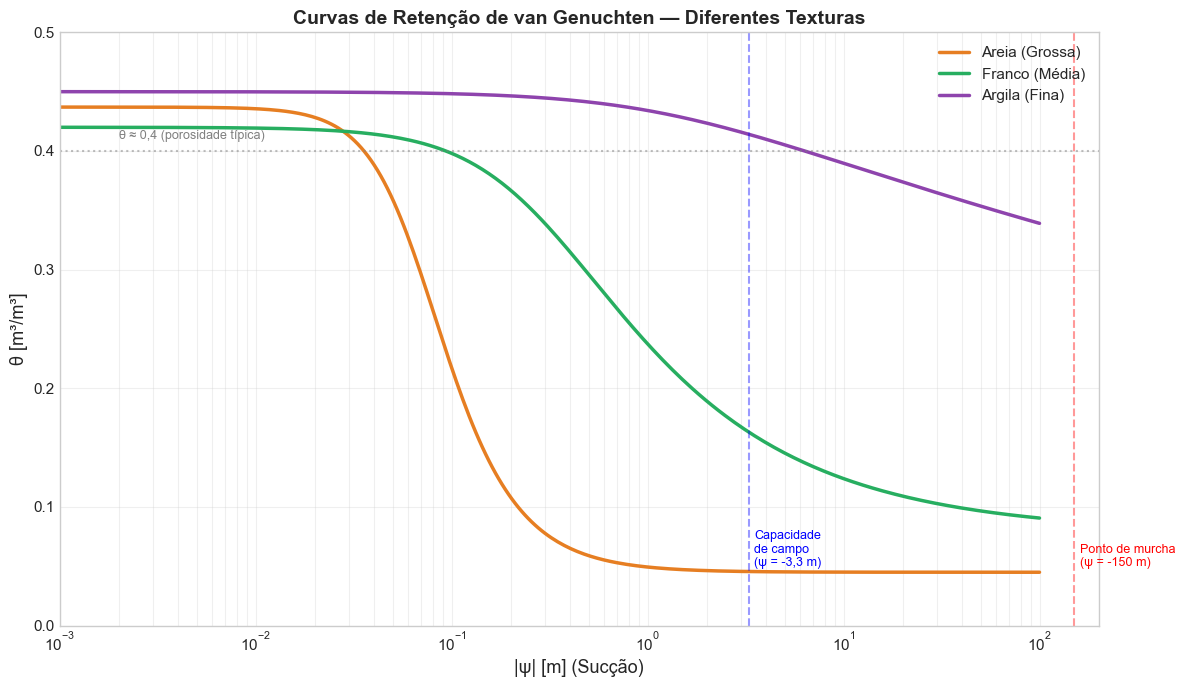

In [6]:
# ============================================================
# GRÁFICO 1: CURVAS DE RETENÇÃO θ(ψ)
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

cores = {'Areia': '#e67e22', 'Franco': '#27ae60', 'Argila': '#8e44ad'}

for nome in solos:
    ax.plot(np.abs(psi_range), resultados[nome]['theta'],
            color=cores[nome], linewidth=2.5,
            label=f'{nome} ({solos[nome]["textura"]})')

# Linhas de referência
ax.axhline(y=0.4, color='gray', linestyle=':', alpha=0.5, linewidth=1.5)
ax.text(0.002, 0.41, 'θ ≈ 0,4 (porosidade típica)', fontsize=9, color='gray')

ax.axvline(x=3.3, color='blue', linestyle='--', alpha=0.4, linewidth=1.5)
ax.text(3.5, 0.05, 'Capacidade\nde campo\n(ψ = -3,3 m)', fontsize=9, color='blue')

ax.axvline(x=150, color='red', linestyle='--', alpha=0.4, linewidth=1.5)
ax.text(160, 0.05, 'Ponto de murcha\n(ψ = -150 m)', fontsize=9, color='red')

ax.set_xlabel('|ψ| [m] (Sucção)', fontsize=13)
ax.set_ylabel('θ [m³/m³]', fontsize=13)
ax.set_title('Curvas de Retenção de van Genuchten — Diferentes Texturas',
             fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3, which='both')
ax.set_xlim(0.001, 200)
ax.set_ylim(0, 0.5)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **Areia:** curva mais íngreme e deslocada para a esquerda (drena rapidamente, baixa retenção).
> - **Argila:** curva mais suave e deslocada para a direita (retém mais água, alta sucção necessária para drenar).
> - **Franco:** comportamento intermediário, ideal para agricultura.
> - A capacidade de campo (ψ = -3,3 m) e o ponto de murcha (ψ = -150 m) são referências agronômicas fundamentais.

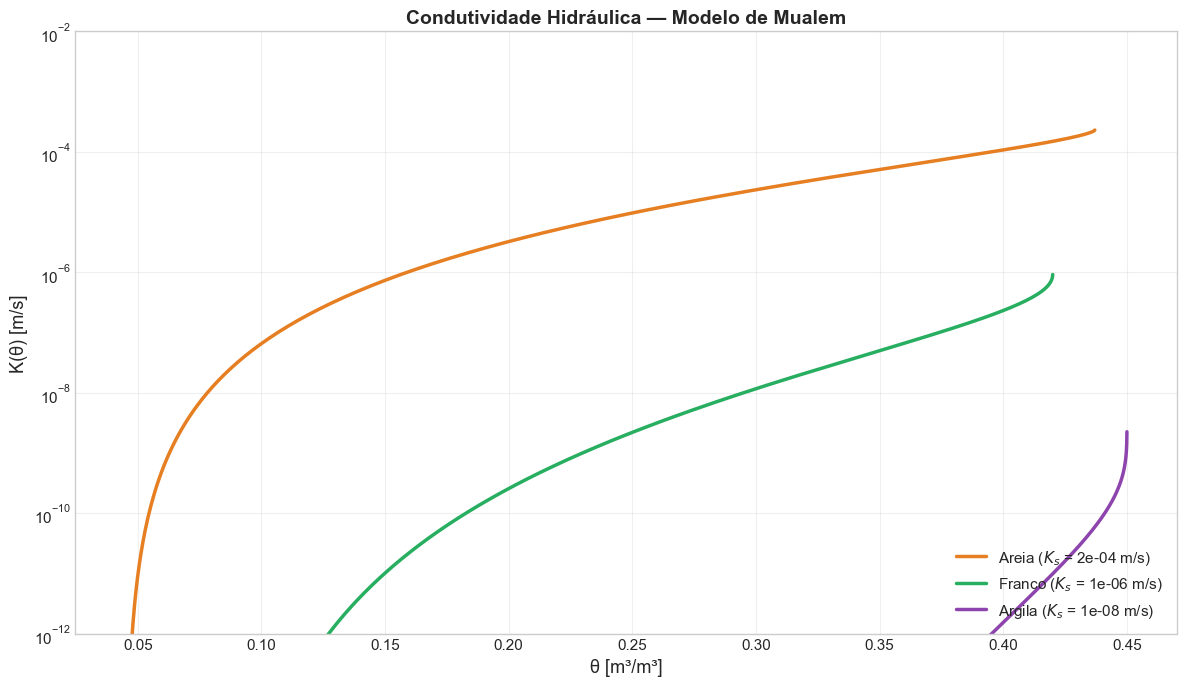

In [7]:
# ============================================================
# GRÁFICO 2: CONDUTIVIDADE HIDRÁULICA K(θ)
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

for nome in solos:
    theta_vals = resultados[nome]['theta']
    K_vals = resultados[nome]['K']
    ax.semilogy(theta_vals, K_vals,
                color=cores[nome], linewidth=2.5,
                label=f'{nome} ($K_s$ = {solos[nome]["K_s"]:.0e} m/s)')

ax.set_xlabel('θ [m³/m³]', fontsize=13)
ax.set_ylabel('K(θ) [m/s]', fontsize=13)
ax.set_title('Condutividade Hidráulica — Modelo de Mualem',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, alpha=0.3, which='both')
ax.set_ylim(1e-12, 1e-2)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A condutividade hidráulica varia **exponencialmente** com o conteúdo de água.
> - Uma redução de 10% na umidade pode reduzir K em 2-3 ordens de grandeza.
> - Isso explica por que solos secos são praticamente impermeáveis.
> - A areia tem K_s ~10⁴× maior que a argila, mas ambas convergem para K → 0 em θ → θ_r.

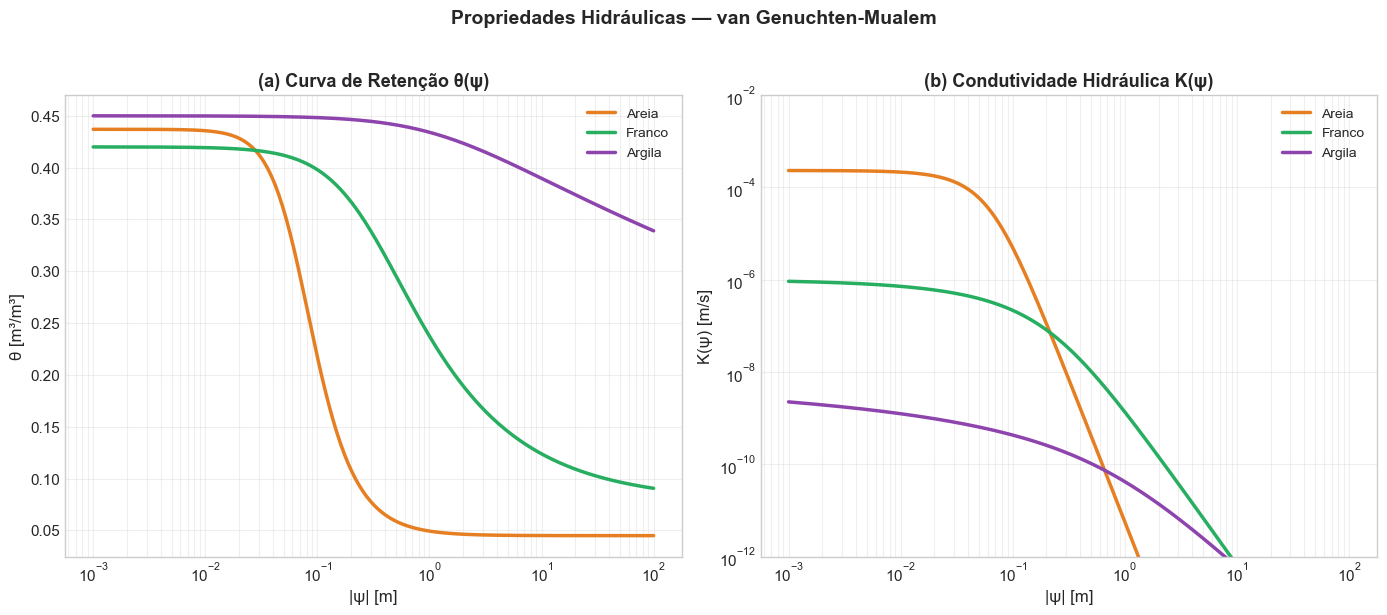

In [8]:
# ============================================================
# GRÁFICO 3: COMPARAÇÃO θ(ψ) E K(θ) LADO A LADO
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Painel 1: θ(ψ)
for nome in solos:
    ax1.plot(np.abs(psi_range), resultados[nome]['theta'],
             color=cores[nome], linewidth=2.5, label=nome)

ax1.set_xlabel('|ψ| [m]', fontsize=12)
ax1.set_ylabel('θ [m³/m³]', fontsize=12)
ax1.set_title('(a) Curva de Retenção θ(ψ)', fontsize=13, fontweight='bold')
ax1.set_xscale('log')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, which='both')

# Painel 2: K(ψ)
for nome in solos:
    ax2.semilogy(np.abs(psi_range), resultados[nome]['K'],
                 color=cores[nome], linewidth=2.5, label=nome)

ax2.set_xlabel('|ψ| [m]', fontsize=12)
ax2.set_ylabel('K(ψ) [m/s]', fontsize=12)
ax2.set_title('(b) Condutividade Hidráulica K(ψ)', fontsize=13, fontweight='bold')
ax2.set_xscale('log')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, which='both')
ax2.set_ylim(1e-12, 1e-2)

plt.suptitle('Propriedades Hidráulicas — van Genuchten-Mualem',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A curva de retenção (a) mostra a capacidade de armazenamento de água.
> - A condutividade (b) mostra a facilidade de fluxo.
> - Solos arenosos drenam rápido (baixa retenção, alta condutividade).
> - Solos argilosos retêm água (alta retenção, baixa condutividade).

---
## 📈 Seção 8: Análise Quantitativa

In [9]:
# ============================================================
# TABELA COMPARATIVA DAS TEXTURAS
# ============================================================

# Calcular propriedades em pontos-chave
psi_cc = -3.3       # Capacidade de campo [m]
psi_pmp = -150.0    # Ponto de murcha permanente [m]

dados_tabela = []
for nome, params in solos.items():
    theta_r = params['theta_r']
    theta_s = params['theta_s']
    alpha = params['alpha']
    n = params['n']
    K_s = params['K_s']

    # Umidade na capacidade de campo
    theta_cc = van_genuchten_theta(np.array([psi_cc]), theta_r, theta_s, alpha, n)[0]

    # Umidade no ponto de murcha
    theta_pmp = van_genuchten_theta(np.array([psi_pmp]), theta_r, theta_s, alpha, n)[0]

    # Água disponível (capacidade de campo - ponto de murcha)
    agua_disponivel = theta_cc - theta_pmp

    # Condutividade na capacidade de campo
    K_cc = van_genuchten_K(np.array([theta_cc]), theta_r, theta_s, K_s, n)[0]

    # Sucção de entrada de ar aproximada
    psi_ae = 1.0 / alpha

    dados_tabela.append({
        'Textura': nome,
        'θ_cc [m³/m³]': f'{theta_cc:.3f}',
        'θ_pmp [m³/m³]': f'{theta_pmp:.3f}',
        'Água disponível [m³/m³]': f'{agua_disponivel:.3f}',
        'K(θ_cc) [m/s]': f'{K_cc:.2e}',
        'ψ_ae [m]': f'{psi_ae:.2f}'
    })

df_comp = pd.DataFrame(dados_tabela)
display(Markdown('### Propriedades Hidráulicas em Pontos-Chave'))
display(Markdown(df_comp.to_markdown(index=False)))

print(f'\n📊 Interpretação:')
print(f'  • Capacidade de campo: ψ = {psi_cc} m')
print(f'  • Ponto de murcha permanente: ψ = {psi_pmp} m')
print(f'  • Água disponível = θ_cc - θ_pmp (água acessível às plantas)')

### Propriedades Hidráulicas em Pontos-Chave

| Textura   |   θ_cc [m³/m³] |   θ_pmp [m³/m³] |   Água disponível [m³/m³] |   K(θ_cc) [m/s] |   ψ_ae [m] |
|:----------|---------------:|----------------:|--------------------------:|----------------:|-----------:|
| Areia     |          0.046 |           0.045 |                     0.001 |        3.47e-15 |       0.07 |
| Franco    |          0.163 |           0.088 |                     0.075 |        2.77e-11 |       0.28 |
| Argila    |          0.414 |           0.331 |                     0.083 |        5.58e-12 |       1.25 |


📊 Interpretação:
  • Capacidade de campo: ψ = -3.3 m
  • Ponto de murcha permanente: ψ = -150.0 m
  • Água disponível = θ_cc - θ_pmp (água acessível às plantas)


---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade das curvas de retenção aos parâmetros $\alpha$ e $n$.

- **$\alpha$:** controla a posição da curva (sucção de entrada de ar)
- **$n$:** controla a inclinação da curva (uniformidade dos poros)

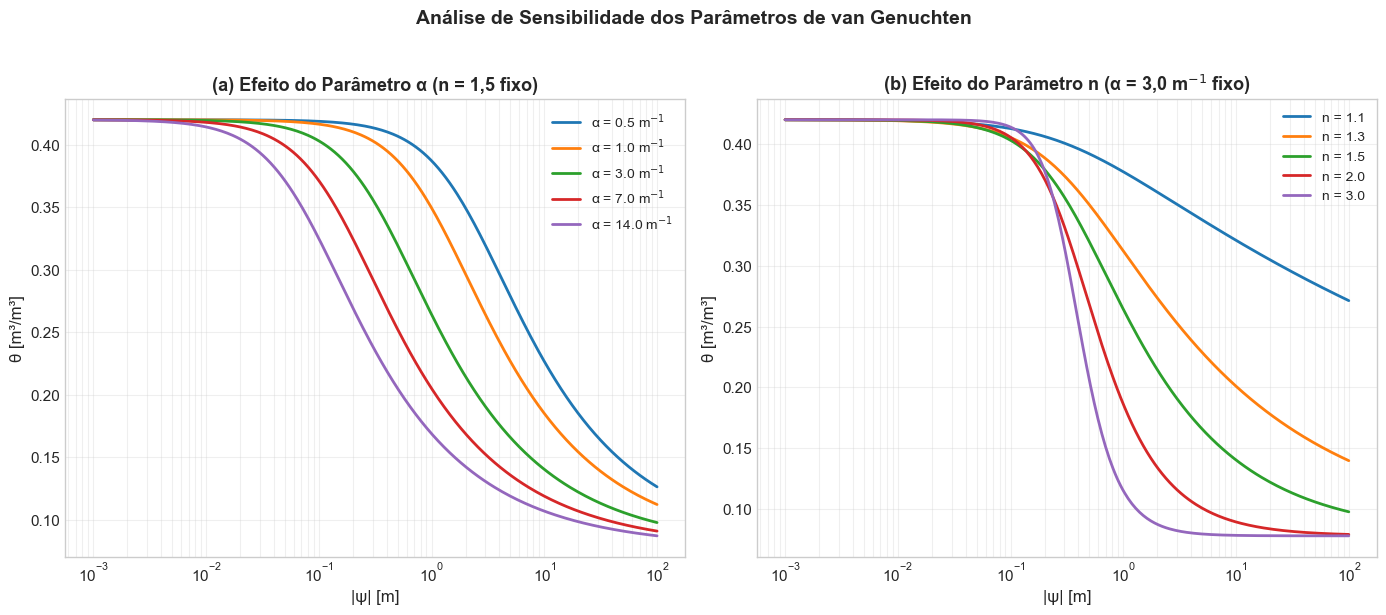

In [13]:
# ============================================================
# SENSIBILIDADE — PARÂMETRO α E n (CORRIGIDO)
# ============================================================

# Manter n fixo e variar α
n_fixo = 1.5
alpha_values = [0.5, 1.0, 3.0, 7.0, 14.0]
theta_r_fixo = 0.078
theta_s_fixo = 0.420

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Painel 1: Efeito de α
for alpha_val in alpha_values:
    theta_vals = van_genuchten_theta(psi_range, theta_r_fixo, theta_s_fixo,
                                     alpha_val, n_fixo)
    ax1.plot(np.abs(psi_range), theta_vals, linewidth=2,
             label=f'α = {alpha_val} m$^{{-1}}$')

ax1.set_xlabel('|ψ| [m]', fontsize=12)
ax1.set_ylabel('θ [m³/m³]', fontsize=12)
ax1.set_title('(a) Efeito do Parâmetro α (n = 1,5 fixo)',
              fontsize=13, fontweight='bold')
ax1.set_xscale('log')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, which='both')

# Painel 2: Efeito de n
alpha_fixo = 3.0
n_values = [1.1, 1.3, 1.5, 2.0, 3.0]

for n_val in n_values:
    theta_vals = van_genuchten_theta(psi_range, theta_r_fixo, theta_s_fixo,
                                     alpha_fixo, n_val)
    ax2.plot(np.abs(psi_range), theta_vals, linewidth=2,
             label=f'n = {n_val}')

ax2.set_xlabel('|ψ| [m]', fontsize=12)
ax2.set_ylabel('θ [m³/m³]', fontsize=12)
ax2.set_title('(b) Efeito do Parâmetro n (α = 3,0 m$^{-1}$ fixo)',
              fontsize=13, fontweight='bold')
ax2.set_xscale('log')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, which='both')

plt.suptitle('Análise de Sensibilidade dos Parâmetros de van Genuchten',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **(a) Efeito de α:** Aumentar α desloca a curva para a **esquerda** (menor sucção necessária para drenar). Solos com α alto (areia) drenam mais facilmente.
> - **(b) Efeito de n:** Aumentar n torna a transição mais **abrupta** (solo mais uniforme). Solos com n baixo (argila) têm transição suave (poros de tamanhos variados).
> - α e n são os parâmetros mais sensíveis na calibração do modelo.

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Textura e retenção de água:** A areia tem baixa retenção (drena rapidamente) e alta condutividade. A argila tem alta retenção (armazena água) e baixa condutividade. O franco é intermediário e ideal para agricultura.

2. **Não-linearidade da condutividade:** $K(\theta)$ varia exponencialmente com $\theta$. Isso significa que pequenos erros na estimativa de $\theta$ podem resultar em grandes erros na previsão de fluxo. A calibração precisa dos parâmetros é essencial.

3. **Parâmetros α e n:** O parâmetro $\alpha$ está relacionado à sucção de entrada de ar ($\psi_{ae} \approx 1/\alpha$). Solos com poros grandes (areia) têm $\alpha$ alto. O parâmetro $n$ indica a uniformidade da distribuição de poros: $n$ alto = poros uniformes (areia); $n$ baixo = poros variados (argila).

4. **Água disponível:** A diferença $\theta_{cc} - \theta_{pmp}$ representa a água acessível às plantas. Solos francos têm a maior água disponível, enquanto areias e argilas têm menos (areia por baixa retenção, argila por alta sucção de murcha).

### Limitações do Modelo

- **Sem histerese:** O modelo não considera o caminho de molhamento vs. secagem. Na realidade, a curva de retenção é diferente nos dois sentidos.
- **Solo homogêneo:** Assume propriedades constantes com a profundidade. Solos reais são estratificados.
- **Sem efeito da temperatura:** A viscosidade da água varia com a temperatura, afetando $K$.
- **Parâmetros constantes:** Na prática, $\alpha$ e $n$ podem variar com a compactação, matéria orgânica e estrutura do solo.
- **Modelo empírico:** Os parâmetros devem ser calibrados com dados experimentais (tensiômetros, câmaras de Richards).

### Aplicações Práticas

- **Agricultura:** Seleção de culturas conforme a capacidade de retenção do solo; planejamento de irrigação.
- **Hidrologia:** Modelagem de infiltração, recarga de aquíferos e escoamento superficial.
- **Engenharia ambiental:** Modelagem de transporte de contaminantes em solos não-saturados.
- **Geotecnia:** Análise de estabilidade de taludes e barragens de terra.

### Conexão com a Teoria

> 📖 **Referência:** O modelo de van Genuchten é descrito em van Genuchten (1980). O modelo de Mualem para condutividade segue Mualem (1976). Os parâmetros para diferentes texturas são tabulados em Saxton & Rawls (2006). A aplicação a problemas ambientais segue Lugon Jr. et al. (2026), Cap. 6, Seções 6.2–6.4.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 6](../notebooks/06_Perculacao_Meio_Poroso.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 6.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>